# Détection automatique des crises d'absence à partir de l'EEG
**Mini-projet de Data Mining — notebook final exécuté — 4 octobre 2026**

**Objectif.** Comparer un arbre de décision, une forêt aléatoire, un KNN et un
SVM, puis reconstruire les périodes de crises. Nous comparons les données
initiales, le sous-échantillonnage des fenêtres normales, le suréchantillonnage
des crises par duplication et SMOTE dans l'espace des caractéristiques.

Le classeur utilisé est **Annotations MAJ.xlsx**. Les horaires sont convertis
par rapport à **DebutTrace**, conformément au message de l'enseignant. Les
signaux restent réels : aucun EEG ou horaire de crise n'est inventé.

**Lecture pour la présentation :** données et annotations (1–4), fenêtres et
caractéristiques (5–6), modèles et comparaison (7–9), détection et erreurs
(10–11), bilan des améliorations et conclusion (12).

## 1. Chargement des données
Le notebook utilise l'interpréteur du projet et les modules `src/` fournis avec
lui. Il s'exécute depuis la racine ou depuis `notebooks/`. Les entraînements sont
conservés avec une empreinte des données, du code, des partitions et des versions.
Mettre `RETRAIN = True` force leur recalcul ; le cache vérifié accélère la présentation.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "Annotations MAJ.xlsx").exists() and (path / "src/eeg_project.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import eeg_presentation as presentation
from src import eeg_project as eeg
from src.eeg_source_validation import validate_exports

OUT = ROOT / "artifacts/final"
FIGURES = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
RETRAIN = False
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")
display(
    Markdown(
        f"**Projet :** `{ROOT.name}` — **Graine :** {eeg.SEED} — **Canal fixé :** {eeg.CHANNEL}"
    )
)

**Projet :** `DM-project` — **Graine :** 42 — **Canal fixé :** EEGF7

In [2]:
cohort, events, audit, all_events, unannotated = eeg.load_annotations(ROOT)
audit.to_csv(OUT / "cohort_audit.csv", index=False)
events.to_csv(OUT / "annotations_seconds.csv", index=False)
display(
    audit.rename(
        columns={
            "record_id": "Enregistrement",
            "excel_row": "Ligne Excel",
            "included": "Retenu",
            "reason": "Décision",
            "actual_events": "Paires réelles",
            "declared_events": "Nombre déclaré",
            "count_mismatch": "Écart de comptage",
            "age": "Âge",
            "sex": "Sexe",
            "duration_s": "Durée du tracé (s)",
        }
    )
)
display(
    Markdown(
        f"**Cohorte retenue : {len(cohort)} enregistrements, {len(events)} crises.** "
        f"Exports sans annotation mise à jour, exclus : {', '.join(unannotated)}."
    )
)

,Enregistrement,Ligne Excel,Âge,Sexe,Nombre déclaré,Paires réelles,Durée du tracé (s),Retenu,Décision,Écart de comptage
0,190304A-E,2,17.000,M,1.000,1,1575.000,True,Retenu,False
1,191113A-D,3,25.000,F,2.000,2,1810.000,True,Retenu,False
2,210406A-F,4,8.000,F,1.000,1,1454.000,True,Retenu,False
3,210427B-C,5,11.000,M,1.000,1,1246.000,True,Retenu,False
4,210504B-C,6,11.000,M,12.000,12,3121.000,False,Crise 1 hors limites du signal,False
5,210914B-A,7,8.000,F,6.000,11,1205.000,True,Retenu,True
6,210928B-B,8,7.000,M,2.000,2,1344.000,True,Retenu,False
7,211027B-C,9,5.000,F,8.000,8,1255.000,True,Retenu,False
8,211104B-D,10,9.000,M,5.000,5,1210.000,True,Retenu,False
9,230406B-A,11,11.000,M,4.000,4,1225.000,False,Doublon conflictuel : aucune ligne choisie arb...,False


**Cohorte retenue : 16 enregistrements, 65 crises.** Exports sans annotation mise à jour, exclus : 200625A-F, 210204B-C, 210208B-G.

Les deux doublons conflictuels `230406B-A` et `230515B-G` sont exclus. Tout
`210504B-C` est exclu parce qu'une crise de 21 608 s dépasse la durée du tracé :
la tronquer ferait presque tout classer en crise. Les onze paires de
`210914B-A` sont conservées malgré `NombreCE = 6`. Les noms `DebutCE5` et
`DebtCE11` sont reconnus par leur numéro. L'absence d'annotation ne signifie
pas absence de crise. Ces décisions sont fixées avant l'entraînement.

## 2. Exploration
**Q1.** Les fichiers MCOS ne sont pas directement lus comme des tableaux EEG
par `scipy.io` ou `h5py`. Les exports déjà présents sont contrôlés contre les
**cellules numériques structurées** du fichier MATLAB original : tous les
blocs, leurs dimensions, les noms ordonnés et les temps doivent correspondre.
Les empreintes SHA-256 invalident le contrôle si un fichier change.

La propriété temporelle MATLAB `millis` identifie les millisecondes. La
fréquence est dérivée du nombre réel d'échantillons par bloc et de l'écart
entre les lignes temporelles, puis vérifiée sur le vecteur `Time` développé.

In [3]:
validation = validate_exports(ROOT, cohort.record_id, OUT)
display(
    validation[
        [
            "record_id",
            "n_channels",
            "n_samples",
            "samples_per_time_row",
            "time_step_s",
            "fs_hz",
            "duration_s",
            "source_values_match",
            "source_names_match",
            "source_times_match",
        ]
    ].rename(
        columns={
            "record_id": "Enregistrement",
            "n_channels": "Canaux",
            "n_samples": "Échantillons",
            "samples_per_time_row": "Échantillons/bloc",
            "time_step_s": "Pas des blocs (s)",
            "fs_hz": "Fréquence mesurée (Hz)",
            "duration_s": "Durée (s)",
            "source_values_match": "Valeurs conformes",
            "source_names_match": "Canaux conformes",
            "source_times_match": "Temps conformes",
        }
    )
)
DEMO = "190304A-E"
t_demo, signal_demo, fs_demo = eeg.load_trace(ROOT, DEMO, validation)
demo_intervals = list(
    events.loc[events.record_id == DEMO, ["start_s", "end_s"]].itertuples(index=False, name=None)
)
info = validation.set_index("record_id").loc[DEMO]
display(
    pd.Series(
        {
            "Enregistrement": DEMO,
            "Lignes": len(signal_demo),
            "Variables (Time + canaux)": int(info.n_channels) + 1,
            "Type EEG exporté": "float32, calculs en float64",
            "Fréquence mesurée (Hz)": fs_demo,
            "Durée couverte (s)": len(signal_demo) / fs_demo,
            "Valeurs manquantes / non finies dans le canal": int((~np.isfinite(signal_demo)).sum()),
        }
    ).to_frame("Q1")
)
display(pd.DataFrame({"Time (s)": t_demo[:8], eeg.CHANNEL: signal_demo[:8]}))

Source vérifiée : 190304A-E


Source vérifiée : 191113A-D


Source vérifiée : 210406A-F


Source vérifiée : 210427B-C


Source vérifiée : 210914B-A


...

Source vérifiée : 230519A-E


Source vérifiée : 230718A-A


,Enregistrement,Canaux,Échantillons,Échantillons/bloc,Pas des blocs (s),Fréquence mesurée (Hz),Durée (s),Valeurs conformes,Canaux conformes,Temps conformes
0,190304A-E,23,403200,256,1.000,256.000,1575.000,True,True,True
1,191113A-D,23,463360,256,1.000,256.000,1810.000,True,True,True
2,210406A-F,23,372224,256,1.000,256.000,1454.000,True,True,True
3,210427B-C,21,318976,256,1.000,256.000,1246.000,True,True,True
4,210914B-A,21,308480,256,1.000,256.000,1205.000,True,True,True
5,210928B-B,21,344064,256,1.000,256.000,1344.000,True,True,True
6,211027B-C,21,321280,256,1.000,256.000,1255.000,True,True,True
7,211104B-D,21,309760,256,1.000,256.000,1210.000,True,True,True
8,220106A-A,23,312576,256,1.000,256.000,1221.000,True,True,True
9,220121B-D,21,330752,256,1.000,256.000,1292.000,True,True,True


,Q1
Enregistrement,190304A-E
Lignes,403200
Variables (Time + canaux),24
Type EEG exporté,"float32, calculs en float64"
Fréquence mesurée (Hz),256.000
Durée couverte (s),1575.000
Valeurs manquantes / non finies dans le canal,0


,Time (s),EEGF7
0,0.000,0.038
1,0.004,0.038
2,0.008,0.038
3,0.012,0.038
4,0.016,0.038
5,0.020,0.038
6,0.023,0.038
7,0.027,0.038


Le canal commun **EEGF7** est fixé avant toute comparaison. Aucun canal n'est
choisi selon les performances du test. Les amplitudes sont exprimées dans
l'unité du fichier : une unité physique non fournie n'est pas inventée.
La durée couverte est `N / fs`, tandis que le dernier temps d'échantillon est
`(N − 1) / fs`. Le contrôle de source est technique, sans validation clinique.

## 3. Visualisations
**Q2.** Le signal complet et un zoom présentent les périodes annotées.
Les titres identifient le tracé et le canal ; les axes indiquent le temps et
l'unité disponible. L'affichage du tracé complet peut être réduit en points,
mais les calculs utilisent tous les échantillons.

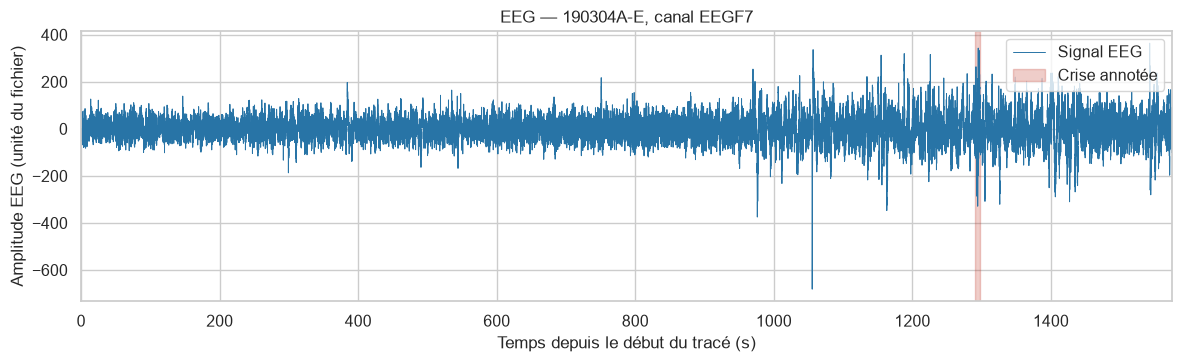

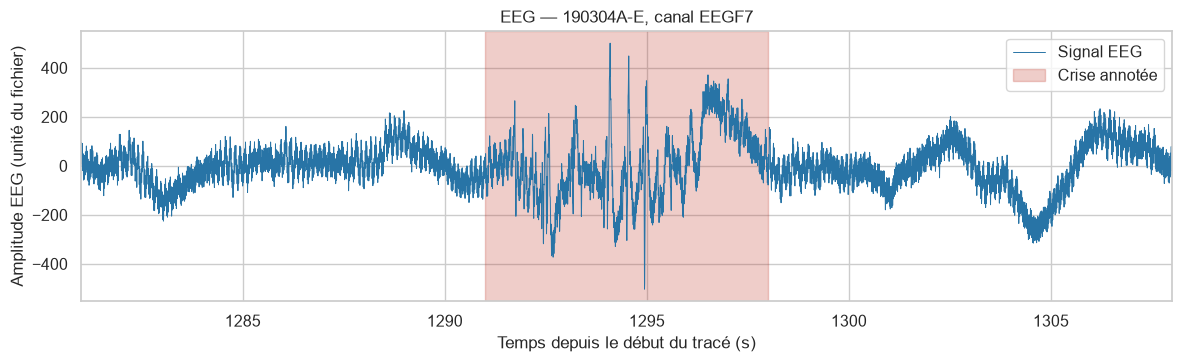

In [4]:
presentation.signal_plot(t_demo, signal_demo, demo_intervals, DEMO, FIGURES, name="signal_annote")
a, b = demo_intervals[0]
presentation.signal_plot(
    t_demo, signal_demo, demo_intervals, DEMO, FIGURES, name="signal_zoom", bounds=(a - 10, b + 10)
)

**Observation visuelle.** Le zoom permet de comparer l'amplitude et la
régularité du tracé pendant l'intervalle annoté et autour de lui. Une décharge
rythmique ou une variation d'amplitude constitue une observation locale ;
elle ne démontre pas à elle seule que les quatre modèles généraliseront.
La FFT et les distributions de caractéristiques complètent cette lecture.

## 4. Traitement des annotations
**Q3–Q4.** Les valeurs sont des **horaires Excel**, et non des durées ou des
fractions de la durée de l'enregistrement. La précision de l'enseignant
fournit l'origine temporelle désormais disponible.

`début_s = (DebCE − DebutTrace) × 86400` ;
`fin_s = (FinCE − DebutTrace) × 86400` ;
`durée_s = fin_s − début_s`.

Pour `190304A-E` : 10:13:35 → début du tracé ; 10:35:06 → début de crise ;
10:35:13 → fin de crise. La crise est **[1291 s, 1298 s]**, soit **7 s**.

,Enregistrement,Crise,Début (s),Fin (s),Durée (s)
0,190304A-E,1,1291.000,1298.000,7.000
1,191113A-D,1,1254.000,1267.000,13.000
2,191113A-D,2,1428.000,1433.000,5.000
3,210406A-F,1,633.000,641.000,8.000
4,210427B-C,1,1031.000,1049.000,18.000
...,...,...,...,...,...
60,230718A-A,3,302.000,313.000,11.000
61,230718A-A,4,430.000,441.000,11.000
62,230718A-A,5,737.000,745.000,8.000
63,230718A-A,6,974.000,986.000,12.000


,Nombre,Duree_totale_s
record_id,,
190304A-E,1,7.000
191113A-D,2,18.000
210406A-F,1,8.000
210427B-C,1,18.000
210914B-A,11,176.000
210928B-B,2,55.000
211027B-C,8,123.000
211104B-D,5,40.000
220106A-A,2,37.000


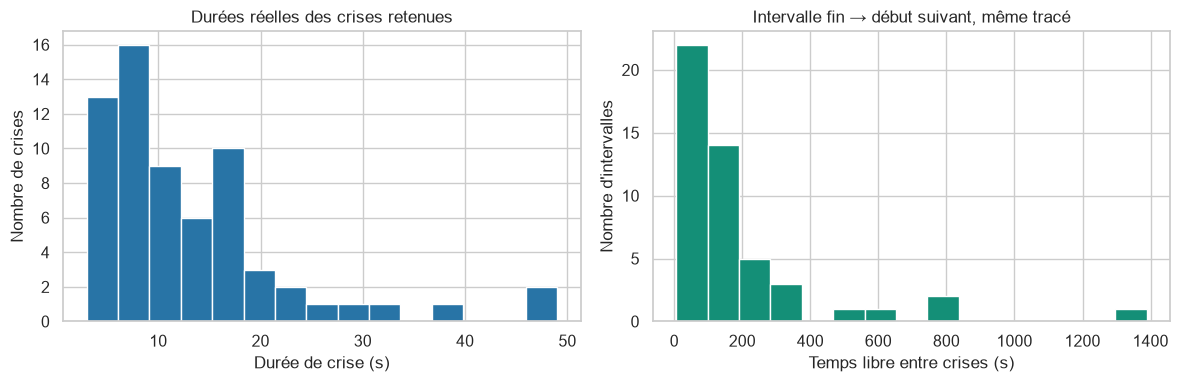

,Q4
Nombre de crises,65.000
Durée moyenne (s),13.462
Durée médiane (s),11.000
Durée minimale (s),3.000
Durée maximale (s),49.000
Intervalle libre moyen fin → début suivant (s),185.857


**Les durées ne sont pas identiques :** de 3 à 49 s, avec une médiane de 11 s. Les intervalles entre crises sont calculés dans un même enregistrement.

In [5]:
display(
    events[["record_id", "event", "start_s", "end_s", "duration_s"]].rename(
        columns={
            "record_id": "Enregistrement",
            "event": "Crise",
            "start_s": "Début (s)",
            "end_s": "Fin (s)",
            "duration_s": "Durée (s)",
        }
    )
)
display(
    events.groupby("record_id").agg(Nombre=("event", "count"), Duree_totale_s=("duration_s", "sum"))
)
gaps = presentation.duration_plots(events, FIGURES)
display(
    pd.Series(
        {
            "Nombre de crises": len(events),
            "Durée moyenne (s)": events.duration_s.mean(),
            "Durée médiane (s)": events.duration_s.median(),
            "Durée minimale (s)": events.duration_s.min(),
            "Durée maximale (s)": events.duration_s.max(),
            "Intervalle libre moyen fin → début suivant (s)": gaps.mean(),
        }
    ).to_frame("Q4")
)
display(
    Markdown(
        f"**Les durées ne sont pas identiques :** de {events.duration_s.min():.0f} "
        f"à {events.duration_s.max():.0f} s, avec une médiane de {events.duration_s.median():.0f} s. "
        "Les intervalles entre crises sont calculés dans un même enregistrement."
    )
)

## 5. Segmentation
**Q5–Q7.** Chaque échantillon reçoit la classe 0 (hors crise) ou 1 (crise).
Le PDF, p. 4, imprime **[début, fin]**. Nous suivons cette convention fermée,
conformément à la demande de fidélité au PDF ; la référence locale utilise
`(début, fin]`, soit un échantillon de différence par début aligné.

Une fenêtre dure **2 s** et recouvre la précédente à **50 %**. Sa classe vaut
1 lorsque **au moins 50 %** de ses échantillons sont en crise. Les fenêtres
incomplètes en fin de tracé sont omises ; les tracés ne sont jamais concaténés.

In [6]:
demo_windows, demo_starts, demo_labels, demo_coverage, demo_mask = eeg.segment_signal(
    t_demo, signal_demo, demo_intervals
)
display(
    pd.DataFrame(
        {
            "Classe": ["Hors crise", "Crise"],
            "Échantillons": [int((~demo_mask).sum()), int(demo_mask.sum())],
            "Fenêtres": [int((demo_labels == 0).sum()), int((demo_labels == 1).sum())],
        }
    )
)
display(
    pd.DataFrame(
        {
            "Début fenêtre (s)": t_demo[demo_starts],
            "Couverture de crise": demo_coverage,
            "Class": demo_labels,
        }
    ).loc[demo_coverage > 0]
)
display(
    Markdown(
        f"**Fenêtre :** {demo_windows.shape[1]} échantillons ; "
        f"**pas :** {demo_starts[1] - demo_starts[0]} échantillons."
    )
)

,Classe,Échantillons,Fenêtres
0,Hors crise,401407,1566
1,Crise,1793,8


,Début fenêtre (s),Couverture de crise,Class
1290,1290.000,0.500,1
1291,1291.000,1.000,1
1292,1292.000,1.000,1
1293,1293.000,1.000,1
1294,1294.000,1.000,1
1295,1295.000,1.000,1
1296,1296.000,1.000,1
1297,1297.000,0.502,1
1298,1298.000,0.002,0


**Fenêtre :** 512 échantillons ; **pas :** 256 échantillons.

## 6. Extraction des caractéristiques
**Q8–Q11.** Une ligne est une fenêtre et les prédicteurs sont exactement les
huit statistiques temporelles et les quatre puissances demandées.

| Temporelles | Définition |
|---|---|
| Moyenne, écart-type, variance | Statistiques de population (`ddof = 0`) |
| Minimum, maximum, amplitude | Amplitude = maximum − minimum |
| RMS, énergie | RMS = √moyenne(x²) ; énergie = Σx² |

La FFT est unilatérale, avec normalisation `|rFFT|²/N²` et doublement hors
composantes DC et Nyquist. La somme de ses puissances est la moyenne du carré
du signal. Les bandes sont Delta [0,5;4[, Theta [4;8[, Alpha [8;13[ et
Beta [13;30[ Hz ; leurs frontières ne sont pas comptées deux fois.

,record_id,start_s,mean,std,variance,min,max,amplitude,rms,energy,power_delta,power_theta,power_alpha,power_beta,Class
0,190304A-E,0.000,-7.871,21.066,443.767,-107.141,73.340,180.481,22.488,258925.860,132.679,42.972,81.238,64.459,0
1,190304A-E,1.000,-21.837,29.018,842.026,-113.609,73.340,186.949,36.317,675275.160,144.354,79.035,187.186,129.990,0
2,190304A-E,2.000,-21.663,30.805,948.959,-113.609,61.944,175.553,37.660,726146.625,143.651,59.527,249.739,129.667,0
3,190304A-E,3.000,-11.172,38.843,1508.773,-117.690,121.617,239.307,40.418,836392.373,154.045,83.076,754.806,149.062,0
4,190304A-E,4.000,1.230,43.737,1912.963,-117.690,136.400,254.090,43.755,980212.270,201.892,193.174,952.496,186.593,0
5,190304A-E,5.000,-6.925,41.671,1736.431,-123.696,136.400,260.096,42.242,913604.326,384.342,178.716,627.745,153.566,0


,Enregistrement,Échantillons,Échantillons crise,Fenêtres,Fenêtres crise,Durée (s),Fréquence (Hz),Canal,Valeurs manquantes
0,190304A-E,403200,1793,1574,8,1575.000,256.000,EEGF7,0
1,191113A-D,463360,4610,1809,20,1810.000,256.000,EEGF7,0
2,210406A-F,372224,2049,1453,9,1454.000,256.000,EEGF7,0
3,210427B-C,318976,4609,1245,19,1246.000,256.000,EEGF7,0
4,210914B-A,308480,45067,1204,187,1205.000,256.000,EEGF7,0
5,210928B-B,344064,14082,1343,57,1344.000,256.000,EEGF7,0
6,211027B-C,321280,31496,1254,131,1255.000,256.000,EEGF7,0
7,211104B-D,309760,10245,1209,45,1210.000,256.000,EEGF7,0
8,220106A-A,312576,9474,1220,39,1221.000,256.000,EEGF7,0
9,220121B-D,330752,12803,1291,53,1292.000,256.000,EEGF7,0


**Q6/Q8 — Cohorte :** 6,005,760 échantillons ; 3.73 % en crise. **Fenêtres :** 23,444, dont 940 crises (4.01 %) et 22,504 hors crise. Ces deux pourcentages portent sur des unités différentes ; le déséquilibre est important.

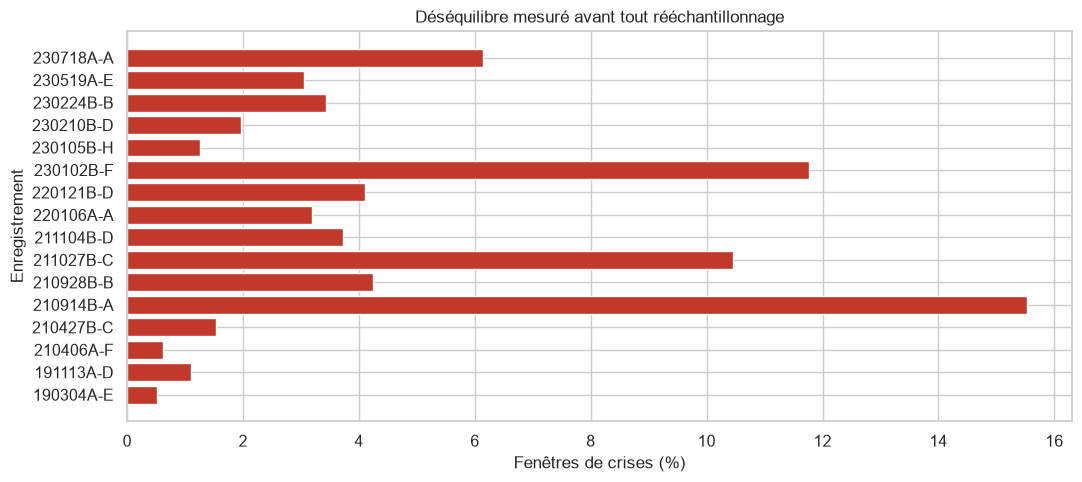

In [7]:
frame, counts = eeg.build_features(ROOT, cohort, events, validation)
frame.to_csv(OUT / "features.csv", index=False)
counts.to_csv(OUT / "class_counts.csv", index=False)
assert frame[eeg.FEATURES].shape[1] == 12
assert np.isfinite(frame[eeg.FEATURES].to_numpy()).all()
display(frame[["record_id", "start_s", *eeg.FEATURES, "Class"]].head(6))
display(
    counts.rename(
        columns={
            "record_id": "Enregistrement",
            "samples": "Échantillons",
            "positive_samples": "Échantillons crise",
            "windows": "Fenêtres",
            "positive_windows": "Fenêtres crise",
            "fs_hz": "Fréquence (Hz)",
            "duration_s": "Durée (s)",
            "channel": "Canal",
            "missing_values": "Valeurs manquantes",
        }
    )
)
display(
    Markdown(
        f"**Q6/Q8 — Cohorte :** {counts.samples.sum():,} échantillons ; "
        f"{100 * counts.positive_samples.sum() / counts.samples.sum():.2f} % en crise. "
        f"**Fenêtres :** {len(frame):,}, dont {int(frame.Class.sum()):,} crises "
        f"({100 * frame.Class.mean():.2f} %) et {int((frame.Class == 0).sum()):,} hors crise. "
        "Ces deux pourcentages portent sur des unités différentes ; le déséquilibre est important."
    )
)
presentation.imbalance_plot(counts, FIGURES)

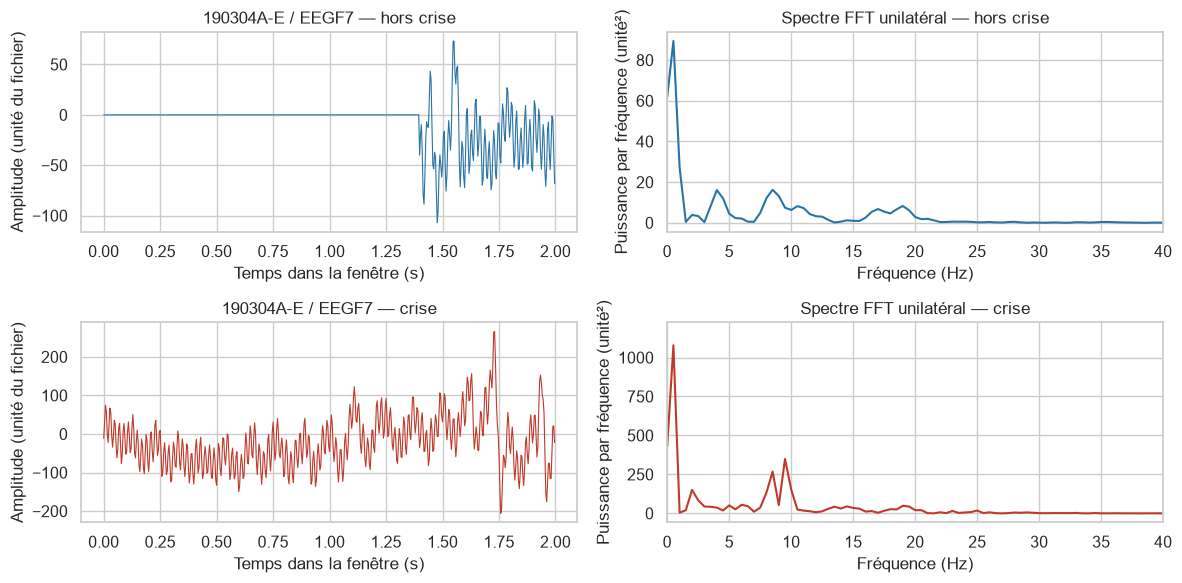

,power_delta,power_theta,power_alpha,power_beta
Classe,,,,
Hors crise,1090.980,108.823,407.043,80.355
Crise,8452.577,1747.129,1849.817,1061.372


In [8]:
presentation.spectra_plot(demo_windows, demo_labels, fs_demo, DEMO, FIGURES)
demo_features = eeg.extract_features(demo_windows, fs_demo)
display(
    demo_features.groupby(demo_labels)[["power_delta", "power_theta", "power_alpha", "power_beta"]]
    .mean()
    .rename_axis("Classe")
    .rename(index={0: "Hors crise", 1: "Crise"})
)

**Q9.** Le spectre et les quatre puissances ci-dessus sont calculés sur le
canal réel. Leur comparaison indique dans quelles bandes l'énergie varie
pour cet enregistrement. Une bande pédagogique, notamment Delta 0,5–4 Hz,
ne doit pas être confondue avec un diagnostic clinique fondé uniquement sur
une fréquence ou avec un résultat commun à tous les tracés.

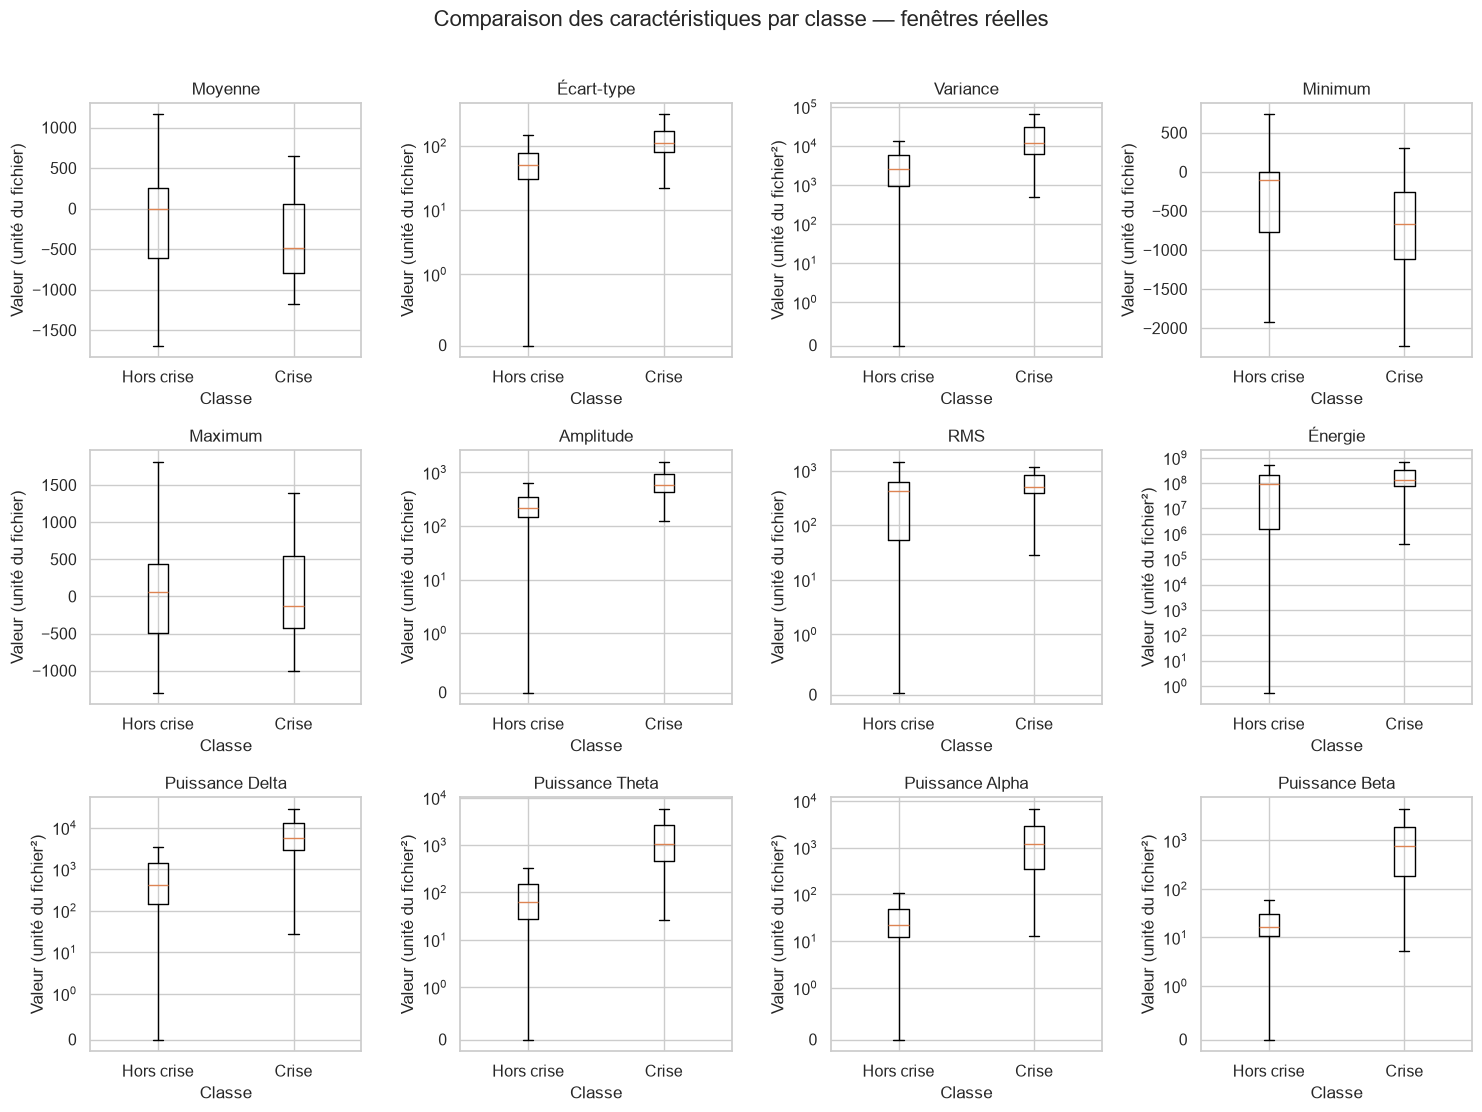

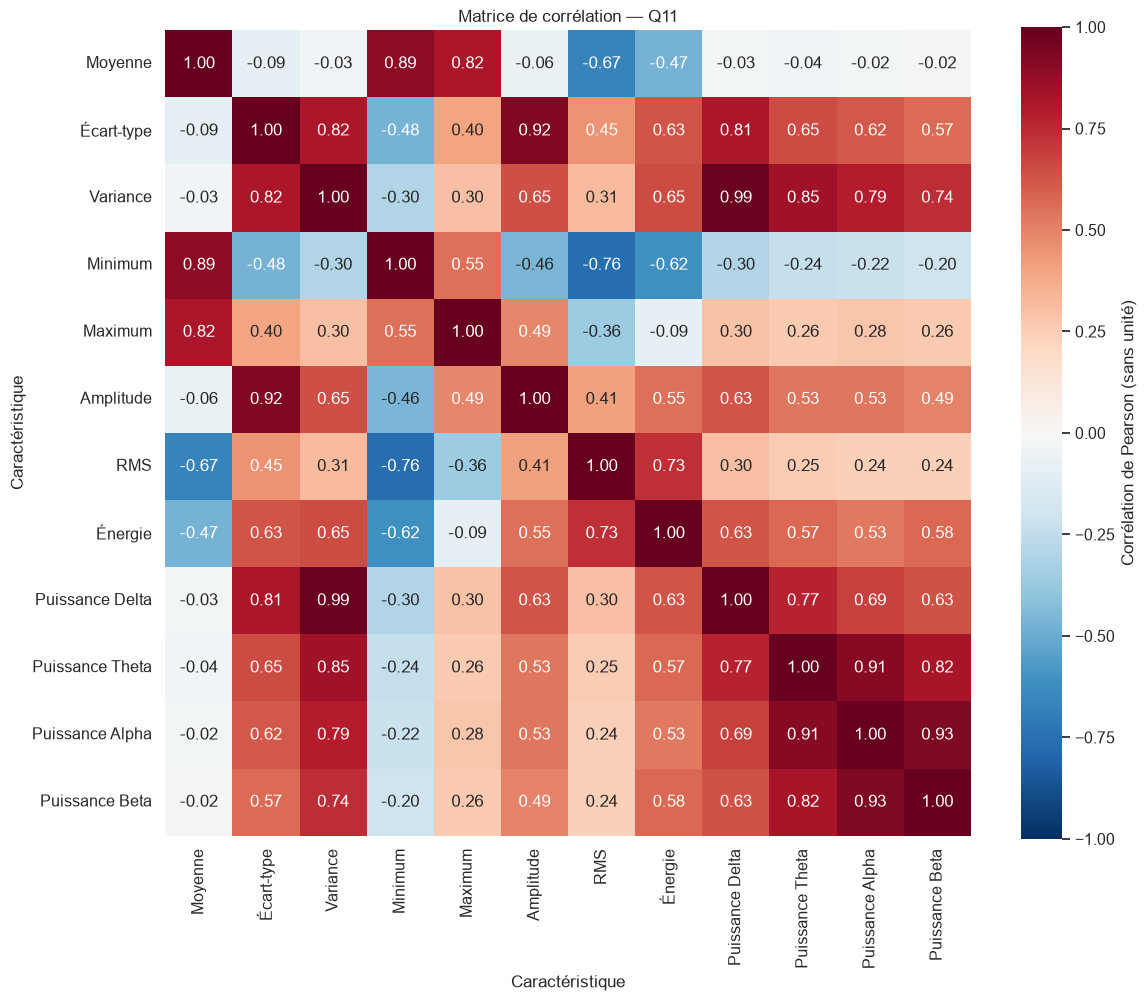

Class               Hors crise         Crise
mean        mean      -183.033      -334.951
            std        518.199       514.864
std         mean        73.746       130.606
            std        138.414        97.730
variance    mean     24596.069     26599.100
            std     395447.780    124522.177
min         mean      -339.371      -682.061
            std        593.342       490.582
max         mean       -19.353        13.261
            std        602.915       637.293
amplitude   mean       320.018       695.322
            std        564.489       456.154
rms         mean       427.538       553.286
            std        379.254       312.366
energy      mean 167227287.386 206640529.904
            std  408547286.232 202752315.310
power_delta mean     17132.612     16986.428
            std     325169.025    121272.274
power_theta mean      1392.078      2024.964
            std      34608.123      2935.276
power_alpha mean       619.190      2067.157
            std      15611.262      2348.498
power_beta  mean       770.030      1737.907
            std      23685.011      2497.109

,Variable 1,Variable 2,Corrélation
32,Variance,Puissance Delta,0.987
131,Puissance Alpha,Puissance Beta,0.932
17,Écart-type,Amplitude,0.923
118,Puissance Theta,Puissance Alpha,0.910
3,Moyenne,Minimum,0.893
33,Variance,Puissance Theta,0.850


,Écart standardisé absolu entre classes
amplitude,0.731
min,0.629
std,0.475
rms,0.362
mean,0.294
power_alpha,0.130
energy,0.122
power_beta,0.057
max,0.053
power_theta,0.026


**Q11 — Réponses.** 1. Les paires fortement corrélées sont celles du tableau ci-dessus. 2. Variance et écart-type, ainsi que énergie et RMS, ont des relations déterministes : il existe une redondance, même si la corrélation de Pearson ne vaut pas exactement 1. 3. Selon cet écart descriptif, les caractéristiques les plus discriminantes sont **amplitude, min, std**. Cette EDA décrit la cohorte ; elle ne sert pas à sélectionner des variables à partir du test. Les 12 prédicteurs sont conservés pour toutes les configurations.

In [9]:
feature_summary, correlation = presentation.feature_plots(frame, FIGURES)
display(feature_summary.T.rename(columns={0: "Hors crise", 1: "Crise"}))
correlation.to_csv(OUT / "feature_correlations.csv")
feature_summary.to_csv(OUT / "features_by_class.csv")
upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
pairs = upper.stack().rename("Corrélation").reset_index()
pairs.columns = ["Variable 1", "Variable 2", "Corrélation"]
display(pairs.loc[pairs["Corrélation"].abs() >= 0.85].sort_values("Corrélation", ascending=False))
pooled_std = np.sqrt(
    (
        frame.loc[frame.Class == 0, eeg.FEATURES].var()
        + frame.loc[frame.Class == 1, eeg.FEATURES].var()
    )
    / 2
)
effect = (
    (
        frame.loc[frame.Class == 1, eeg.FEATURES].mean()
        - frame.loc[frame.Class == 0, eeg.FEATURES].mean()
    )
    / pooled_std.replace(0, np.nan)
).abs()
display(
    effect.sort_values(ascending=False).rename("Écart standardisé absolu entre classes").to_frame()
)
display(
    Markdown(
        "**Q11 — Réponses.** "
        "1. Les paires fortement corrélées sont celles du tableau ci-dessus. "
        "2. Variance et écart-type, ainsi que énergie et RMS, ont des relations déterministes : "
        "il existe une redondance, même si la corrélation de Pearson ne vaut pas exactement 1. "
        f"3. Selon cet écart descriptif, les caractéristiques les plus discriminantes sont "
        f"**{', '.join(effect.sort_values(ascending=False).head(3).index)}**. "
        "Cette EDA décrit la cohorte ; elle ne sert pas à sélectionner des variables à partir du test. "
        "Les 12 prédicteurs sont conservés pour toutes les configurations."
    )
)

## 7. Entraînement des modèles
**Q12.** Une séparation groupée empêche les fenêtres partageant des
échantillons de se retrouver dans les deux ensembles. Des partitions fixées
avec la graine 42 sont comparées **uniquement selon les effectifs et proportions**
pour approcher 80/20 et une stratification des classes. Les groupes indivisibles
rendent le ratio exact impossible ; les proportions réalisées sont publiées.

Trois plis de validation stratifiée groupée, **dans l'apprentissage seulement**,
servent à sélectionner le F1 moyen. Le rappel et la précision départagent les
égalités. Les hyperparamètres sont fixés à l'avance : arbre (profondeur 8,
feuille minimale 5), forêt (200 arbres, feuille minimale 2), KNN (5 voisins,
poids de distance), SVM RBF (`C = 1`). Ils ne sont pas ajustés sur le test.

In [10]:
train_indices, test_indices, folds = eeg.choose_split(frame)
train_records = set(frame.iloc[train_indices].record_id)
test_records = set(frame.iloc[test_indices].record_id)
assert train_records.isdisjoint(test_records)
split_table = pd.DataFrame(
    [
        {
            "Partition": name,
            "Enregistrements": subset.record_id.nunique(),
            "Fenêtres": len(subset),
            "Part des fenêtres (%)": 100 * len(subset) / len(frame),
            "Fenêtres crise": int(subset.Class.sum()),
            "Crises (%)": 100 * subset.Class.mean(),
        }
        for name, subset in [
            ("Apprentissage", frame.iloc[train_indices]),
            ("Test réservé", frame.iloc[test_indices]),
        ]
    ]
)
display(split_table)
display(
    pd.DataFrame(
        {
            "Apprentissage": pd.Series(sorted(train_records)),
            "Test réservé": pd.Series(sorted(test_records)),
        }
    ).fillna("")
)
split_table.to_csv(OUT / "split_summary.csv", index=False)

,Partition,Enregistrements,Fenêtres,Part des fenêtres (%),Fenêtres crise,Crises (%)
0,Apprentissage,12,18519,78.992,729,3.936
1,Test réservé,4,4925,21.008,211,4.284


,Apprentissage,Test réservé
0,190304A-E,211104B-D
1,191113A-D,220106A-A
2,210406A-F,220121B-D
3,210427B-C,230718A-A
4,210914B-A,
5,210928B-B,
6,211027B-C,
7,230102B-F,
8,230105B-H,
9,230210B-D,


Chaque configuration est un pipeline **StandardScaler → rééchantillonnage
éventuel → modèle**. Normalisation et équilibrage sont réajustés uniquement
sur chaque pli d'apprentissage. L'égalité des effectifs concerne l'entraînement,
jamais le test. Les identifiants et horaires servent à regrouper et reconstruire
les fenêtres ; ils ne font pas partie des prédicteurs.

SMOTE interpole des caractéristiques de crises réelles de l'apprentissage ;
ses lignes ne sont ni de nouveaux patients, ni des crises réellement annotées.
Les deux stratégies proposées sont ainsi comparées à une référence sans
équilibrage, avec la duplication comme contrôle de l'interpolation.

In [11]:
experiment = eeg.run_training(frame, train_indices, test_indices, folds, OUT, force=RETRAIN)
cv_display = experiment["cv_summary"].copy()
cv_display["strategy"] = cv_display.strategy.map(eeg.STRATEGIES)
cv_display["model"] = cv_display.model.map(eeg.MODELS)
display(
    cv_display[["strategy", "model", "precision_mean", "recall_mean", "f1_mean", "f1_std"]].rename(
        columns={
            "strategy": "Stratégie",
            "model": "Modèle",
            "precision_mean": "Précision CV",
            "recall_mean": "Rappel CV",
            "f1_mean": "F1 moyen CV",
            "f1_std": "Écart-type F1 CV",
        }
    )
)
selected_strategy, selected_model = experiment["best"].split("__")
display(
    Markdown(
        f"**Choix fixé en validation interne : {eeg.MODELS[selected_model]} "
        f"avec {eeg.STRATEGIES[selected_strategy].lower()}.** "
        "Le classement du test ne change pas ce choix."
    )
)

Les 16 entraînements vérifiés sont relus du cache ; données, code et partitions identiques.


,Stratégie,Modèle,Précision CV,Rappel CV,F1 moyen CV,Écart-type F1 CV
0,SMOTE,Arbre de décision,0.298,0.714,0.402,0.107
1,Sous-échantillonnage,Forêt aléatoire,0.263,0.838,0.392,0.126
2,Sans équilibrage,Forêt aléatoire,0.510,0.407,0.389,0.177
3,Sans équilibrage,Arbre de décision,0.411,0.494,0.388,0.184
4,Suréchantillonnage,Forêt aléatoire,0.468,0.390,0.383,0.125
5,Suréchantillonnage,Arbre de décision,0.258,0.727,0.361,0.114
6,SMOTE,Forêt aléatoire,0.407,0.385,0.354,0.096
7,Sous-échantillonnage,Arbre de décision,0.205,0.824,0.325,0.076
8,SMOTE,KNN,0.239,0.352,0.262,0.107
9,Suréchantillonnage,KNN,0.256,0.299,0.262,0.107


**Choix fixé en validation interne : Arbre de décision avec smote.** Le classement du test ne change pas ce choix.

## 8. Évaluation
**Q13.** Le test garde toutes ses fenêtres réelles et son déséquilibre naturel.
Les quatre métriques demandées et les matrices de confusion sont présentées
pour chaque configuration. La classe positive est toujours la crise.

,Accuracy,Précision,Rappel,F1,TN,FP,FN,TP
Toujours hors crise,0.957,0.000,0.000,0.000,4714,0,211,0


,Stratégie,Modèle,Accuracy,Précision,Rappel,F1,TP,FP,FN,TN
0,Sans équilibrage,Arbre de décision,0.979,0.728,0.810,0.767,171,64,40,4650
1,Sans équilibrage,Forêt aléatoire,0.986,0.843,0.815,0.829,172,32,39,4682
2,Sans équilibrage,KNN,0.959,0.551,0.232,0.327,49,40,162,4674
3,Sans équilibrage,SVM,0.969,0.889,0.303,0.452,64,8,147,4706


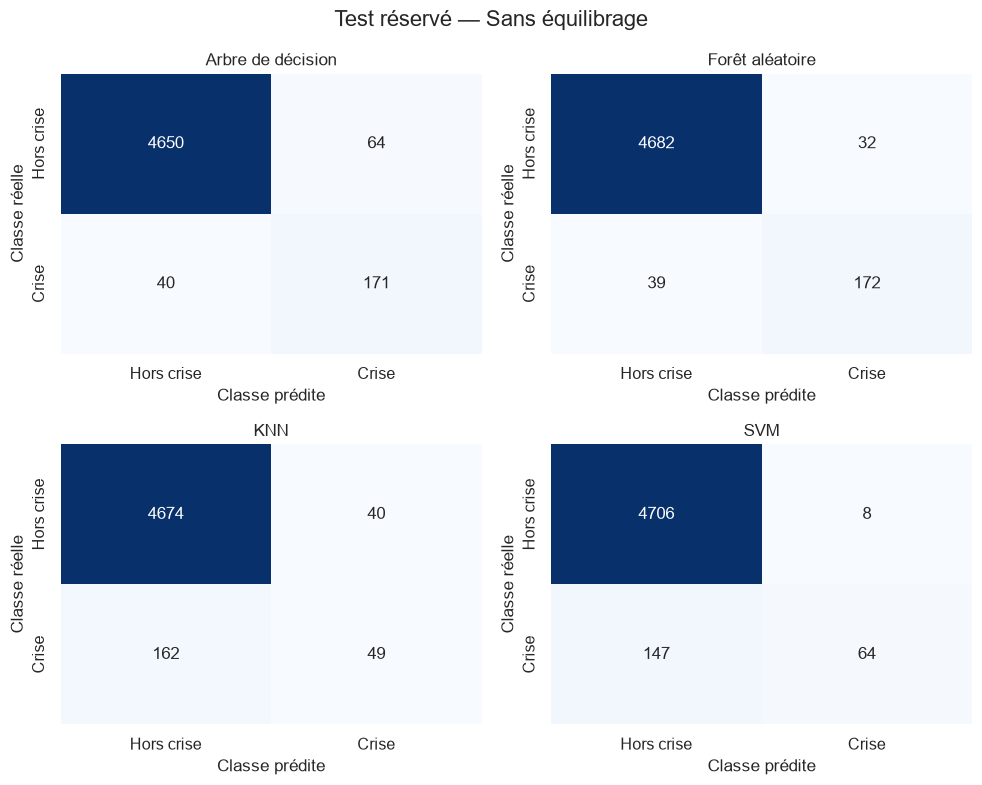

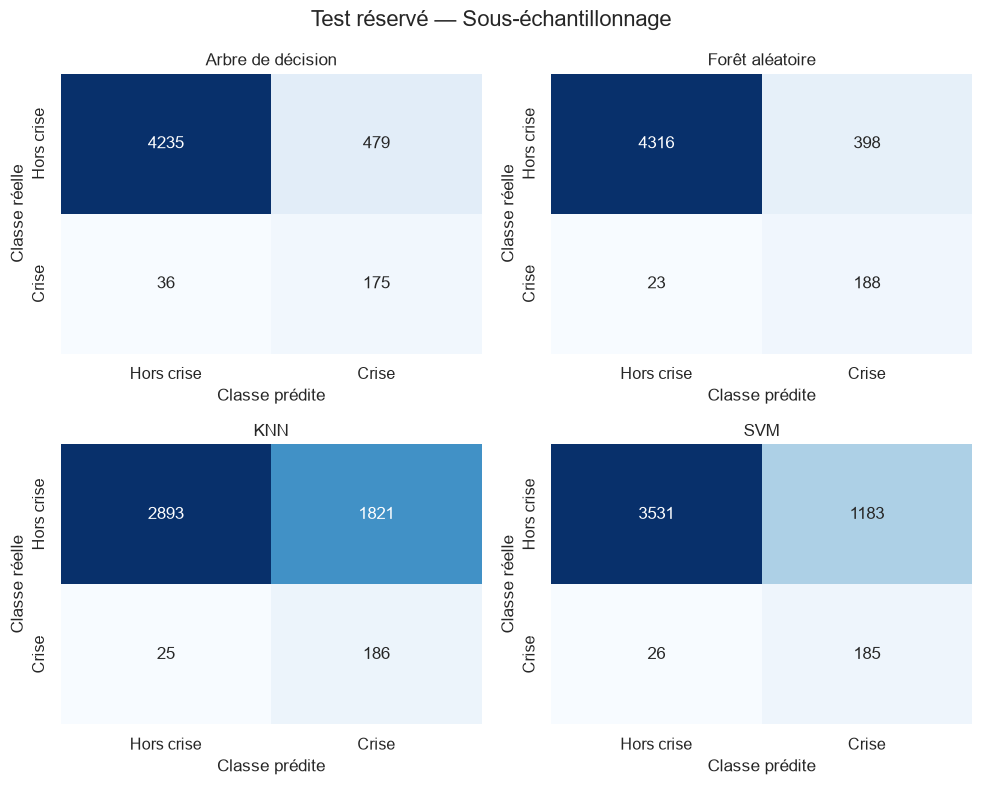

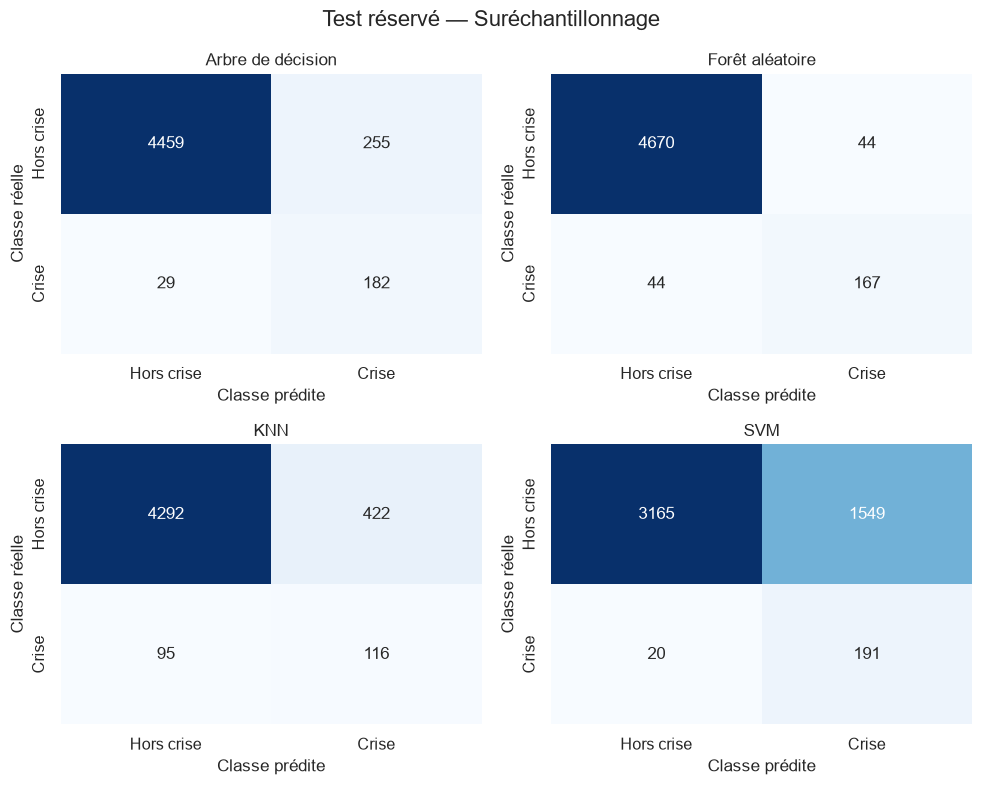

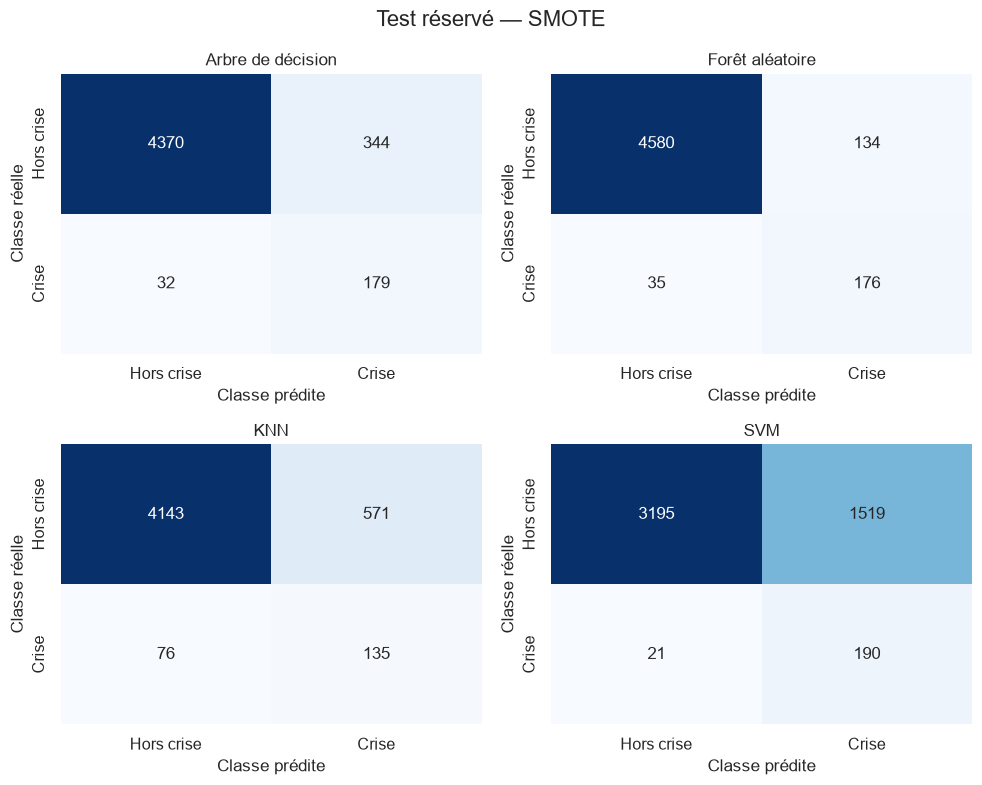

In [12]:
y_test = frame.iloc[test_indices].Class.to_numpy()
baseline = eeg.score_predictions(y_test, np.zeros(len(y_test), dtype=int))
display(
    pd.DataFrame([baseline], index=["Toujours hors crise"]).rename(
        columns={"accuracy": "Accuracy", "precision": "Précision", "recall": "Rappel", "f1": "F1"}
    )
)
display(presentation.metrics_table(experiment, strategy="original"))
presentation.confusion_plots(experiment, FIGURES)

**Pourquoi l'accuracy est trompeuse.** La baseline peut avoir une accuracy
élevée tout en manquant toutes les crises. Le **rappel** est essentiel pour
rendre ces omissions visibles ; la **précision** mesure la fiabilité des
fenêtres signalées. Un rappel parfait en prédisant « crise » partout ne
suffirait pas. Le **F1** sert ici de compromis pour sélectionner le modèle,
accompagné des deux métriques et du nombre de fausses alertes. Une précision
n'est pas un nombre d'alarmes par heure.

## 9. Comparaison
Le tableau contient **16 configurations**, évaluées sur les mêmes fenêtres.
Les performances de validation interne et du test sont distinctes.
Aucune configuration n'est retouchée après lecture des résultats du test.

,Stratégie,Modèle,Accuracy,Précision,Rappel,F1,TP,FP,FN,TN
0,Sans équilibrage,Arbre de décision,0.979,0.728,0.810,0.767,171,64,40,4650
1,Sans équilibrage,Forêt aléatoire,0.986,0.843,0.815,0.829,172,32,39,4682
2,Sans équilibrage,KNN,0.959,0.551,0.232,0.327,49,40,162,4674
3,Sans équilibrage,SVM,0.969,0.889,0.303,0.452,64,8,147,4706
4,Sous-échantillonnage,Arbre de décision,0.895,0.268,0.829,0.405,175,479,36,4235
5,Sous-échantillonnage,Forêt aléatoire,0.915,0.321,0.891,0.472,188,398,23,4316
6,Sous-échantillonnage,KNN,0.625,0.093,0.882,0.168,186,1821,25,2893
7,Sous-échantillonnage,SVM,0.755,0.135,0.877,0.234,185,1183,26,3531
8,Suréchantillonnage,Arbre de décision,0.942,0.416,0.863,0.562,182,255,29,4459
9,Suréchantillonnage,Forêt aléatoire,0.982,0.791,0.791,0.791,167,44,44,4670


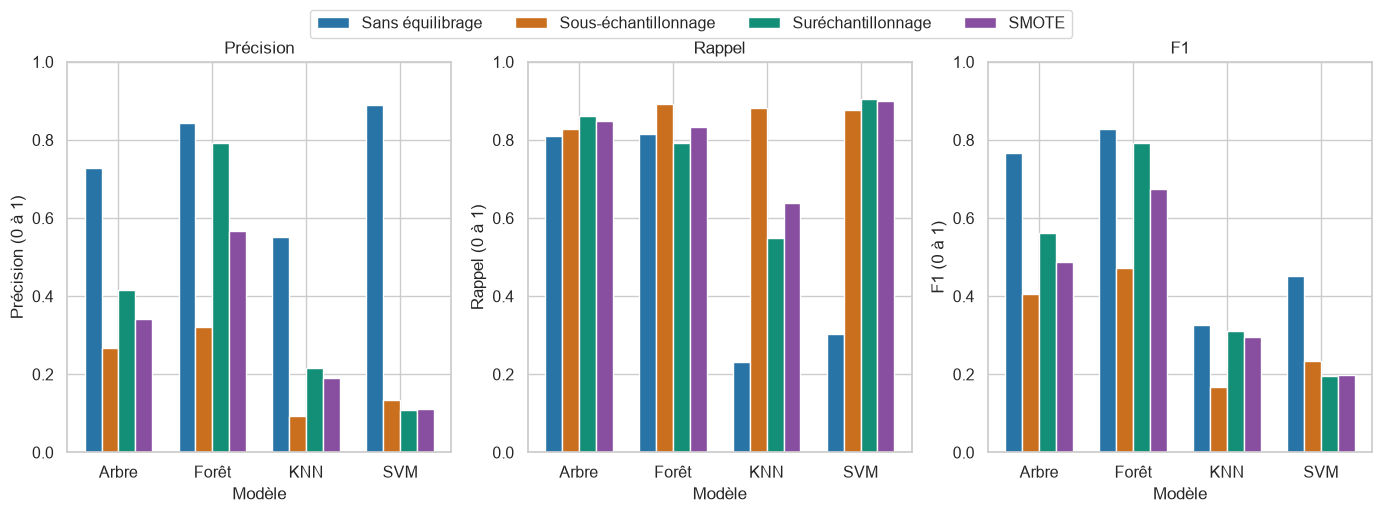

Le modèle **sélectionné en CV** obtient sur le test une précision de **0.342**, un rappel de **0.848** et un F1 de **0.488**. Le plus grand F1 **observé sur ce test** est 0.829, pour Forêt aléatoire / Sans équilibrage. Cette différence illustre la variabilité entre enregistrements ; elle ne conduit pas à sélectionner rétrospectivement le modèle sur le test.

In [13]:
display(presentation.metrics_table(experiment))
presentation.comparison_plot(experiment, FIGURES)
selected_test = experiment["results"].set_index("configuration").loc[experiment["best"]]
best_observed = experiment["results"].sort_values("f1", ascending=False).iloc[0]
observed_strategy, observed_model = best_observed.configuration.split("__")
display(
    Markdown(
        f"Le modèle **sélectionné en CV** obtient sur le test une précision de "
        f"**{selected_test.precision:.3f}**, un rappel de **{selected_test.recall:.3f}** "
        f"et un F1 de **{selected_test.f1:.3f}**. "
        f"Le plus grand F1 **observé sur ce test** est {best_observed.f1:.3f}, "
        f"pour {eeg.MODELS[observed_model]} / {eeg.STRATEGIES[observed_strategy]}. "
        "Cette différence illustre la variabilité entre enregistrements ; elle ne conduit "
        "pas à sélectionner rétrospectivement le modèle sur le test."
    )
)

## 10. Détection temporelle
**Q14.** Les supports temporels des fenêtres positives sont fusionnés lorsqu'ils
se touchent ou se recouvrent, dans un même tracé. Les bornes sont celles des
fenêtres, sans déplacer l'origine ni fixer une durée de crise arbitraire.
Cette reconstruction a une résolution liée au pas de 1 s et n'est pas une
estimation clinique précise des limites.

Pour l'analyse événementielle complémentaire, l'appariement est un à un,
avec **IoU ≥ 0,3** fixée avant calcul : intersection des intervalles divisée
par leur union. Le meilleur modèle de validation interne est utilisé.

,Enregistrement,Crise détectée,Début prédit (s),Fin prédite (s)
0,211104B-D,1,51.000,60.000
1,211104B-D,2,108.000,110.000
2,211104B-D,3,252.000,260.000
3,211104B-D,4,384.000,386.000
4,211104B-D,5,387.000,392.000
...,...,...,...,...
197,230718A-A,80,1172.000,1178.000
198,230718A-A,81,1191.000,1193.000
199,230718A-A,82,1195.000,1197.000
200,230718A-A,83,1198.000,1200.000


,Enregistrement,Résultat,Début réel (s),Fin réelle (s),Début prédit (s),Fin prédite (s),IoU
0,211104B-D,TP,253.000,259.000,252.000,260.000,0.750
1,211104B-D,TP,384.000,392.000,387.000,392.000,0.625
2,211104B-D,TP,555.000,565.000,555.000,566.000,0.909
3,211104B-D,TP,806.000,814.000,807.000,815.000,0.778
4,211104B-D,TP,896.000,904.000,896.000,903.000,0.875
8,220106A-A,TP,335.000,354.000,339.000,353.000,0.737
9,220106A-A,TP,1151.000,1169.000,1152.000,1170.000,0.895
31,220121B-D,TP,105.000,120.000,104.000,123.000,0.789
32,220121B-D,TP,330.000,348.000,334.000,353.000,0.609
33,220121B-D,TP,598.000,615.000,598.000,621.000,0.739


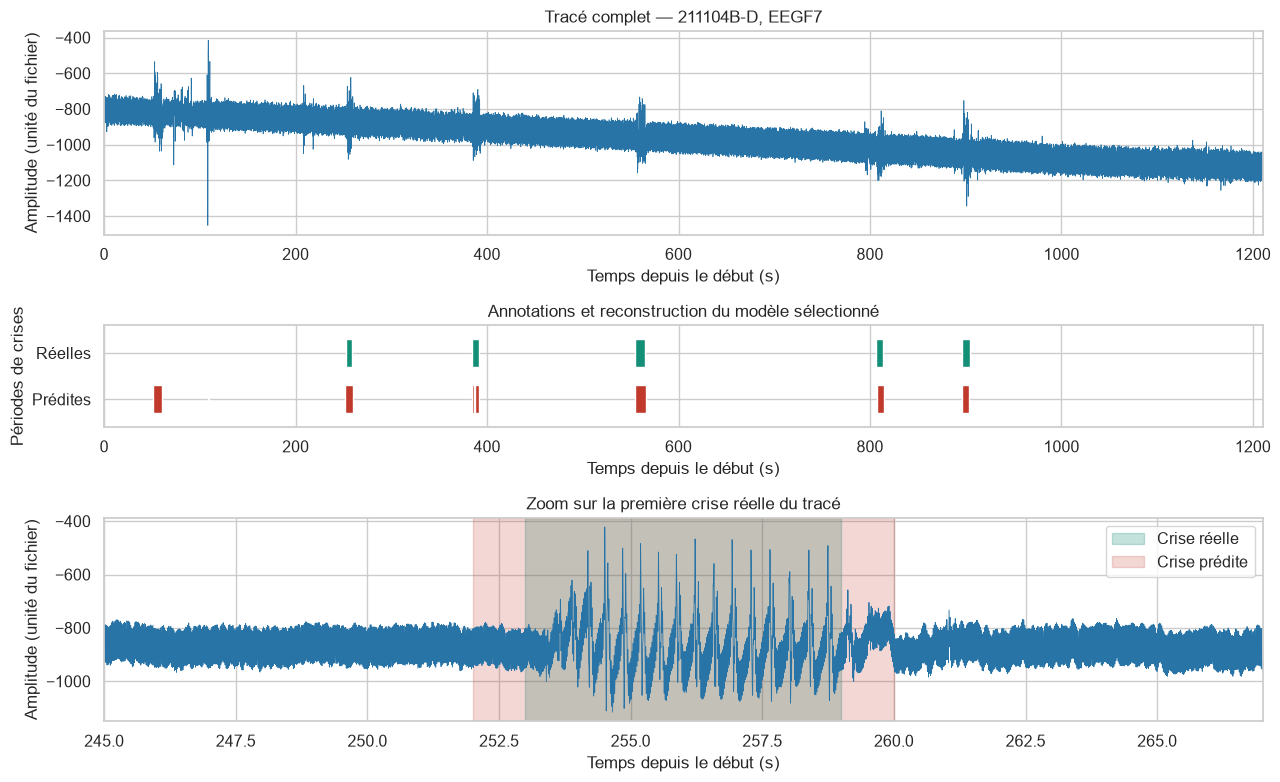

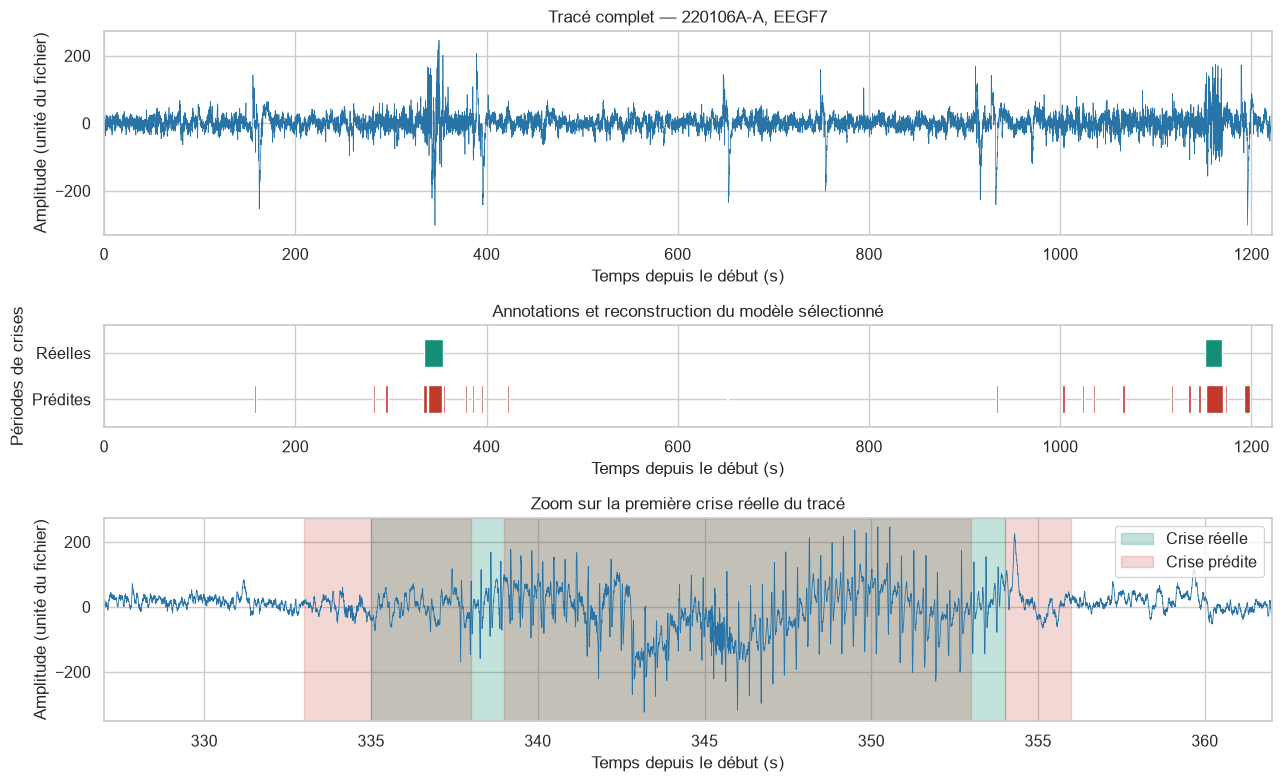

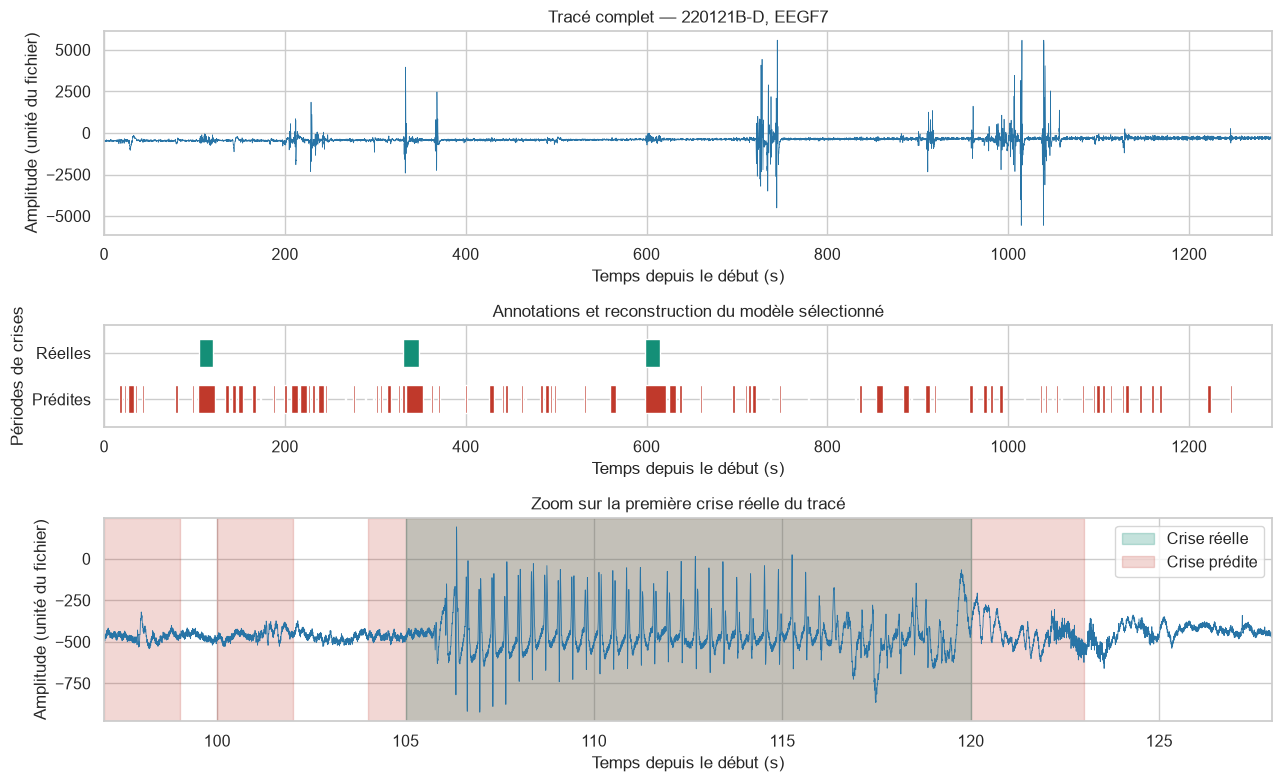

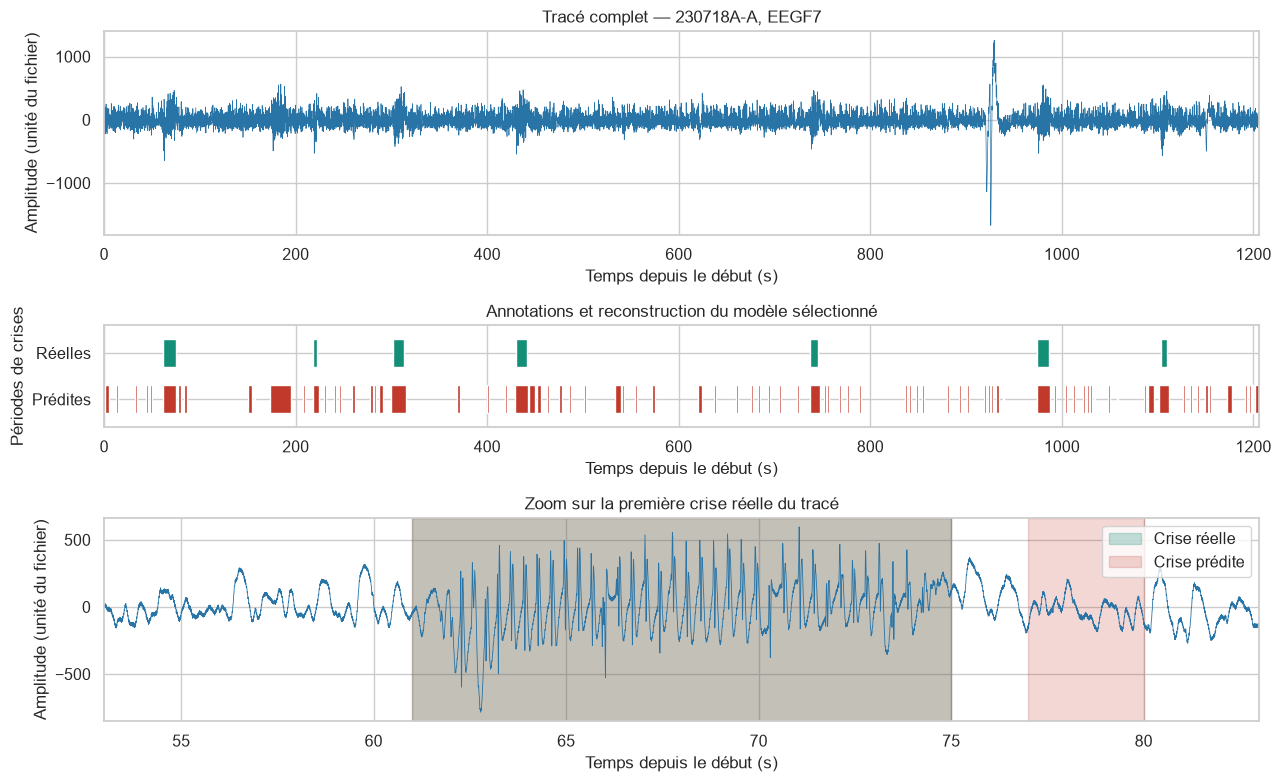

In [14]:
temporal = eeg.temporal_analysis(frame, events, experiment, OUT)
display(
    temporal["predicted"].rename(
        columns={
            "record_id": "Enregistrement",
            "event": "Crise détectée",
            "start_s": "Début prédit (s)",
            "end_s": "Fin prédite (s)",
        }
    )
)
display(
    temporal["details"]
    .loc[temporal["details"].status != "FP"]
    .rename(
        columns={
            "record_id": "Enregistrement",
            "status": "Résultat",
            "true_start_s": "Début réel (s)",
            "true_end_s": "Fin réelle (s)",
            "pred_start_s": "Début prédit (s)",
            "pred_end_s": "Fin prédite (s)",
        }
    )
)
presentation.temporal_plots(ROOT, events, validation, temporal, FIGURES)

## 11. Analyse des erreurs
Les TP, FP, FN et TN au niveau des fenêtres sont affichés par enregistrement.
Les événements correctement appariés, manqués ou non appariés sont comptés
séparément. Un événement réel peut produire plusieurs fenêtres positives ;
les deux niveaux ne doivent pas être confondus. Il n'existe pas de nombre
naturel de TN au niveau des événements continus.

In [15]:
display(
    temporal["windows"].rename(
        columns={
            "record_id": "Enregistrement",
            "accuracy": "Accuracy",
            "precision": "Précision",
            "recall": "Rappel",
            "f1": "F1",
        }
    )
)
display(
    temporal["events"].rename(
        columns={
            "record_id": "Enregistrement",
            "true_events": "Crises réelles",
            "predicted_events": "Crises prédites",
            "precision": "Précision",
            "recall": "Rappel",
            "f1": "F1",
        }
    )
)
totals = temporal["events"][["TP", "FP", "FN"]].sum()
event_recall = totals.TP / (totals.TP + totals.FN) if totals.TP + totals.FN else 0
event_precision = totals.TP / (totals.TP + totals.FP) if totals.TP + totals.FP else 0
test_hours = validation.loc[validation.record_id.isin(test_records), "duration_s"].sum() / 3600
display(
    Markdown(
        f"**Événements, IoU ≥ 0,3 :** {totals.TP} TP, {totals.FP} FP, {totals.FN} FN ; "
        f"rappel {event_recall:.3f}, précision {event_precision:.3f}. "
        f"**Événements non appariés par heure : {totals.FP / test_hours:.1f}.**"
    )
)
display(temporal["details"].loc[temporal["details"].status == "FP"].head(10))

,Enregistrement,Accuracy,Précision,Rappel,F1,TN,FP,FN,TP
0,211104B-D,0.980,0.769,0.667,0.714,1155,9,15,30
1,220106A-A,0.970,0.517,0.795,0.626,1152,29,8,31
2,220121B-D,0.864,0.224,0.943,0.362,1065,173,3,50
3,230718A-A,0.885,0.338,0.919,0.495,998,133,6,68


,Enregistrement,Crises réelles,Crises prédites,TP,FP,FN,Précision,Rappel,F1
0,211104B-D,5,8,5,3,0,0.625,1.000,0.769
1,220106A-A,2,23,2,21,0,0.087,1.000,0.160
2,220121B-D,3,87,3,84,0,0.034,1.000,0.067
3,230718A-A,7,84,7,77,0,0.083,1.000,0.154


**Événements, IoU ≥ 0,3 :** 17 TP, 185 FP, 0 FN ; rappel 1.000, précision 0.084. **Événements non appariés par heure : 135.1.**

,record_id,status,true_start_s,true_end_s,pred_start_s,pred_end_s,IoU
5,211104B-D,FP,NaN,NaN,51.000,60.000,0.000
6,211104B-D,FP,NaN,NaN,108.000,110.000,0.000
7,211104B-D,FP,NaN,NaN,384.000,386.000,0.000
10,220106A-A,FP,NaN,NaN,157.000,159.000,0.000
11,220106A-A,FP,NaN,NaN,281.000,283.000,0.000
12,220106A-A,FP,NaN,NaN,294.000,297.000,0.000
13,220106A-A,FP,NaN,NaN,333.000,338.000,0.000
14,220106A-A,FP,NaN,NaN,354.000,356.000,0.000
15,220106A-A,FP,NaN,NaN,377.000,379.000,0.000
16,220106A-A,FP,NaN,NaN,385.000,387.000,0.000


Un événement non apparié peut être un artefact, une détection trop fragmentée,
un intervalle mal borné ou une anomalie non couverte par les annotations. Sans
revue clinique indépendante, sa cause n'est pas affirmée. Les fenêtres FN
peuvent correspondre à un début, une fin ou une portion d'une crise malgré un
événement finalement apparié. Les chronologies ci-dessus permettent de
distinguer ces situations ; les moyennes globales ne les remplacent pas.

## 12. Améliorations
Les deux solutions proposées ont été **réellement mesurées** sur le test
commun. Le sous-échantillonnage garde toutes les fenêtres de crises de
l'apprentissage et un nombre égal de fenêtres normales. Le suréchantillonnage
conserve les normales et multiplie les positives, par duplication ou SMOTE.

Prélever « 3 % des normales » ne donne pas exactement le même effectif que
« 3 % du total » : la règle correcte est `N_normal_retenu = N_crise`.
Ces opérations concernent des fenêtres déjà construites, pas un signal
artificiel obtenu en concaténant des morceaux.

In [16]:
resampling = (
    experiment["results"]
    .drop_duplicates("strategy")[
        [
            "strategy",
            "train_positive_before",
            "train_negative_before",
            "train_positive_after",
            "train_negative_after",
        ]
    ]
    .copy()
)
resampling.strategy = resampling.strategy.map(eeg.STRATEGIES)
resampling.columns = [
    "Stratégie",
    "Crises avant",
    "Normales avant",
    "Crises après",
    "Normales après",
]
display(resampling)
reference = experiment["results"].loc[experiment["results"].strategy == "original"]
before_after = experiment["results"].merge(
    reference[["model", "precision", "recall", "f1"]], on="model", suffixes=("", "_reference")
)
for metric in ("precision", "recall", "f1"):
    before_after["delta_" + metric] = before_after[metric] - before_after[metric + "_reference"]
before_after = before_after.loc[
    before_after.strategy != "original",
    [
        "strategy",
        "model",
        "precision",
        "delta_precision",
        "recall",
        "delta_recall",
        "f1",
        "delta_f1",
    ],
]
before_after.strategy = before_after.strategy.map(eeg.STRATEGIES)
before_after.model = before_after.model.map(eeg.MODELS)
before_after.columns = [
    "Stratégie",
    "Modèle",
    "Précision",
    "Δ précision",
    "Rappel",
    "Δ rappel",
    "F1",
    "Δ F1",
]
display(before_after)
before_after.to_csv(OUT / "improvements_before_after.csv", index=False)
display(
    Markdown(
        "**Interprétation :** un gain de rappel doit être lu avec le changement de "
        "précision et de F1. L'équilibrage ne crée pas d'information indépendante "
        "et ne garantit pas un meilleur résultat pour chaque modèle."
    )
)

,Stratégie,Crises avant,Normales avant,Crises après,Normales après
0,Sans équilibrage,729,17790,729,17790
4,Sous-échantillonnage,729,17790,729,729
8,Suréchantillonnage,729,17790,17790,17790
12,SMOTE,729,17790,17790,17790


,Stratégie,Modèle,Précision,Δ précision,Rappel,Δ rappel,F1,Δ F1
4,Sous-échantillonnage,Arbre de décision,0.268,-0.460,0.829,0.019,0.405,-0.362
5,Sous-échantillonnage,Forêt aléatoire,0.321,-0.522,0.891,0.076,0.472,-0.357
6,Sous-échantillonnage,KNN,0.093,-0.458,0.882,0.649,0.168,-0.159
7,Sous-échantillonnage,SVM,0.135,-0.754,0.877,0.573,0.234,-0.218
8,Suréchantillonnage,Arbre de décision,0.416,-0.311,0.863,0.052,0.562,-0.205
9,Suréchantillonnage,Forêt aléatoire,0.791,-0.052,0.791,-0.024,0.791,-0.037
10,Suréchantillonnage,KNN,0.216,-0.335,0.550,0.318,0.310,-0.017
11,Suréchantillonnage,SVM,0.110,-0.779,0.905,0.602,0.196,-0.256
12,SMOTE,Arbre de décision,0.342,-0.385,0.848,0.038,0.488,-0.279
13,SMOTE,Forêt aléatoire,0.568,-0.275,0.834,0.019,0.676,-0.153


**Interprétation :** un gain de rappel doit être lu avec le changement de précision et de F1. L'équilibrage ne crée pas d'information indépendante et ne garantit pas un meilleur résultat pour chaque modèle.

### Conclusion et limites
Le notebook compare quatre familles de modèles et quatre stratégies avec des
horaires corrigés et une séparation sans partage d'enregistrement. Le choix
du modèle repose sur la validation interne et ses erreurs restent visibles.

La cohorte de **16 tracés / 65 crises** est petite ; le test comprend quatre
tracés. Les plis groupés et leurs écarts-types rendent cette variabilité
visible. La séparation par enregistrement ne garantit pas une séparation
par patient, faute d'identifiant patient fiable. Le canal unique, les artefacts,
les annotations exclues, les unités d'amplitude et la plausibilité des
interpolations SMOTE limitent la portée des conclusions. Les données ne sont
pas une validation clinique externe.

Parmi les perspectives : résoudre les annotations conflictuelles, valider sur
une autre cohorte, explorer d'autres canaux ou fenêtres et ajuster les seuils
uniquement en validation sur l'apprentissage. Aucune performance de ces
perspectives n'est inventée.

**Sources :** énoncé `mini-prjet-data-mining.pdf`, classeur `Annotations MAJ.xlsx`
et message de l'enseignant ; [pipeline imbalanced-learn](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html),
[rééchantillonnage et fuites](https://imbalanced-learn.org/stable/common_pitfalls.html),
[StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html),
[SMOTE, Chawla et al.](https://arxiv.org/abs/1106.1813).

In [17]:
report_path = presentation.write_report(
    ROOT, cohort, events, counts, frame, experiment, temporal, gaps
)
assert train_records.isdisjoint(test_records)
assert len(experiment["results"]) == 16 and len(experiment["cv"]) == 48
assert validation[["source_values_match", "source_names_match", "source_times_match"]].all().all()
display(
    Markdown(
        "**Livrables générés :** notebook exécuté, rapport français `reports/RAPPORT_FINAL_EEG.md`, "
        "figures, tableaux CSV, contrôles source et modèle sélectionné dans `artifacts/final/`."
    )
)

**Livrables générés :** notebook exécuté, rapport français `reports/RAPPORT_FINAL_EEG.md`, figures, tableaux CSV, contrôles source et modèle sélectionné dans `artifacts/final/`.